1. Import Libraries

In [1]:

# Import pandas to load, organize, and analyze tabular data
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import Seaborn for attractive statistical visualizations
import seaborn as sns

# Import the file upload and download tools from Google Colab
from google.colab import files

# Import train_test_split to divide data into training and testing sets
from sklearn.model_selection import train_test_split

# Import RandomForestClassifier to build the Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Import SimpleImputer to fill missing feature values
from sklearn.impute import SimpleImputer

# Import accuracy_score to calculate prediction accuracy
from sklearn.metrics import accuracy_score

# Import classification_report to calculate precision, recall, and F1-score
from sklearn.metrics import classification_report

# Import confusion_matrix to count correct and incorrect predictions
from sklearn.metrics import confusion_matrix

# Import roc_curve to calculate points for the ROC curve
from sklearn.metrics import roc_curve

# Import roc_auc_score to calculate the area under the ROC curve
from sklearn.metrics import roc_auc_score

# Import joblib to save the trained model to a file
import joblib

# Set Seaborn's default graph style to make plots easier to read
sns.set_theme(style="whitegrid")

# Display a message confirming that the libraries were imported
print("All libraries imported successfully!")


All libraries imported successfully!


2. Upload Dataset

In [2]:

# Open a file picker so you can upload your CSV dataset to Colab
uploaded = files.upload()

# Get the name of the first uploaded file
filename = next(iter(uploaded))

# Read the uploaded CSV file into a pandas DataFrame
df = pd.read_csv(filename)

# Print a message confirming that the dataset was loaded
print("Dataset uploaded successfully!")

# Display the uploaded file's name
print("File name:", filename)

# Display the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

# Display the first five rows to inspect the dataset
display(df.head())


Saving customer_purchase_data.csv to customer_purchase_data.csv
Dataset uploaded successfully!
File name: customer_purchase_data.csv
Dataset shape: (1500, 9)


,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus
0,40,1,66120.267939,8,0,30.568601,0,5,1
1,20,1,23579.773583,4,2,38.240097,0,5,0
2,27,1,127821.306432,11,2,31.633212,1,0,1
3,24,1,137798.623120,19,3,46.167059,0,4,1
4,31,1,99300.964220,19,1,19.823592,0,0,1


3. Explore dataset


In [3]:

# Display all column names in the dataset
print("Column names:")
print(df.columns.tolist())

# Print information about columns, data types, and non-missing values
print("\nDataset information:")
df.info()

# Count missing values in each column and display them as a table
print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

# Calculate descriptive statistics for numerical and categorical columns
print("\nStatistical summary:")
display(df.describe(include="all").T)


Column names:
['Age', 'Gender', 'AnnualIncome', 'NumberOfPurchases', 'ProductCategory', 'TimeSpentOnWebsite', 'LoyaltyProgram', 'DiscountsAvailed', 'PurchaseStatus']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1500 non-null   int64  
 1   Gender              1500 non-null   int64  
 2   AnnualIncome        1500 non-null   float64
 3   NumberOfPurchases   1500 non-null   int64  
 4   ProductCategory     1500 non-null   int64  
 5   TimeSpentOnWebsite  1500 non-null   float64
 6   LoyaltyProgram      1500 non-null   int64  
 7   DiscountsAvailed    1500 non-null   int64  
 8   PurchaseStatus      1500 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 105.6 KB

Missing values in each column:


,Missing Values
Age,0
Gender,0
AnnualIncome,0
NumberOfPurchases,0
ProductCategory,0
TimeSpentOnWebsite,0
LoyaltyProgram,0
DiscountsAvailed,0
PurchaseStatus,0



Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Age,1500.0,44.298667,15.537259,18.000000,31.000000,45.000000,57.000000,70.000000
Gender,1500.0,0.504667,0.500145,0.000000,0.000000,1.000000,1.000000,1.000000
AnnualIncome,1500.0,84249.164338,37629.493078,20001.512518,53028.979155,83699.581476,117167.772858,149785.176481
NumberOfPurchases,1500.0,10.420000,5.887391,0.000000,5.000000,11.000000,15.000000,20.000000
ProductCategory,1500.0,2.012667,1.428005,0.000000,1.000000,2.000000,3.000000,4.000000
TimeSpentOnWebsite,1500.0,30.469040,16.984392,1.037023,16.156700,30.939516,44.369863,59.991105
LoyaltyProgram,1500.0,0.326667,0.469151,0.000000,0.000000,0.000000,1.000000,1.000000
DiscountsAvailed,1500.0,2.555333,1.705152,0.000000,1.000000,3.000000,4.000000,5.000000
PurchaseStatus,1500.0,0.432000,0.495520,0.000000,0.000000,0.000000,1.000000,1.000000


4. Visualize Dataset

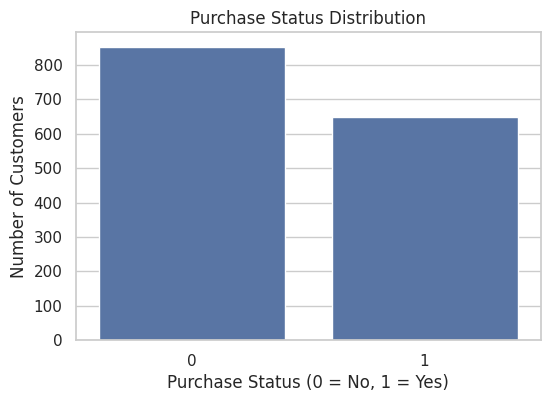

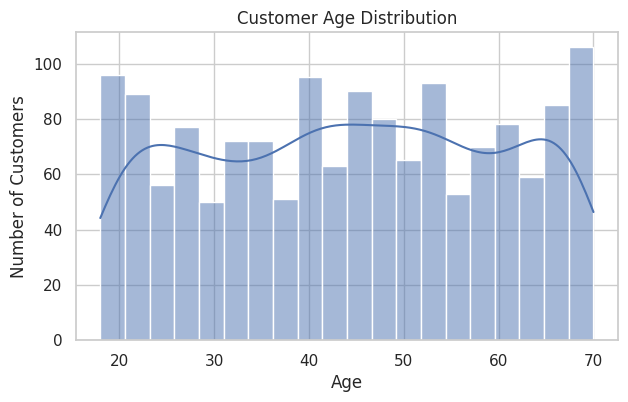

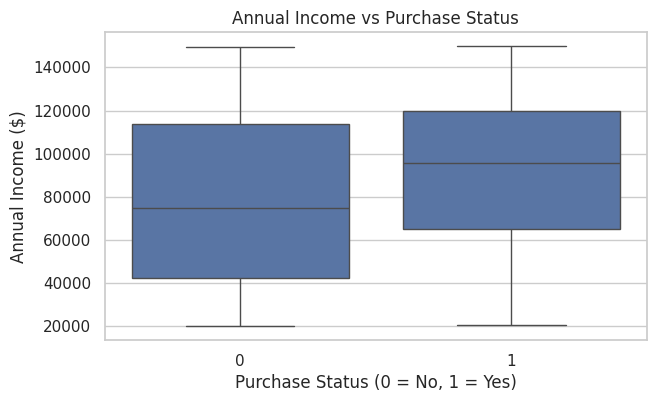

In [5]:

# Create the first figure for purchase status distribution
plt.figure(figsize=(6, 4))

# Draw a count plot showing the number of customers in each class
sns.countplot(data=df, x="PurchaseStatus")

# Add a title to the graph
plt.title("Purchase Status Distribution")

# Label the horizontal axis
plt.xlabel("Purchase Status (0 = No, 1 = Yes)")

# Label the vertical axis
plt.ylabel("Number of Customers")

# Display the first graph
plt.show()


# Create the second figure for customer age distribution
plt.figure(figsize=(7, 4))

# Draw a histogram showing the distribution of customer ages
sns.histplot(data=df, x="Age", bins=20, kde=True)

# Add a title to the graph
plt.title("Customer Age Distribution")

# Label the horizontal axis
plt.xlabel("Age")

# Label the vertical axis
plt.ylabel("Number of Customers")

# Display the second graph
plt.show()


# Create the third figure for income and purchase status
plt.figure(figsize=(7, 4))

# Find the correct income column name automatically
income_column = next(
    (col for col in df.columns
     if col.strip().lower().replace("_", " ") in
     ["annual income", "annualincome"]),
    None
)

# Draw the boxplot if the income column exists
if income_column is not None:
    sns.boxplot(data=df, x="PurchaseStatus", y=income_column)

    # Add a title to the graph
    plt.title("Annual Income vs Purchase Status")

    # Label the horizontal axis
    plt.xlabel("Purchase Status (0 = No, 1 = Yes)")

    # Label the vertical axis
    plt.ylabel("Annual Income ($)")

    # Display the third graph
    plt.show()
else:
    plt.close()
    print("Income column not found. Available columns:", df.columns.tolist())


5.Prepare input features and target

In [7]:

# Define the eight input features used for prediction
features = [
    "Age",                       # Customer's age
    "Gender",                    # Gender encoded as 0 or 1
    "Annual Income",             # Customer's annual income
    "Number of Purchases",       # Number of previous purchases
    "Product Category",          # Encoded product category
    "Time Spent on Website",     # Website time in minutes
    "Loyalty Program",           # Loyalty membership encoded as 0 or 1
    "Discounts Availed"          # Number of discounts used
]

# Define the target column that the model will predict
target = "PurchaseStatus"

# Function to standardize column names for matching
def normalize_column(name):
    return "".join(str(name).lower().split()).replace("_", "").replace("-", "")

# Create a mapping of standardized names to actual dataset column names
column_mapping = {
    normalize_column(col): col for col in df.columns
}

# Match the required feature names to the actual column names
matched_columns = {}
missing_columns = []

for col in features + [target]:
    normalized_name = normalize_column(col)

    if normalized_name in column_mapping:
        matched_columns[col] = column_mapping[normalized_name]
    else:
        missing_columns.append(col)

# Stop if any required columns are not available
if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}\n"
        f"Available dataset columns: {df.columns.tolist()}"
    )

# Select the required columns and rename them consistently
data = df[
    [matched_columns[col] for col in features + [target]]
].copy()

data.columns = features + [target]

# Convert all required columns to numeric values
for col in features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove rows with missing target values
data = data.dropna(subset=[target])

# Keep only valid target values: 0 (No Purchase) and 1 (Purchase)
data = data[data[target].isin([0, 1])]

# Remove rows with missing input feature values
data = data.dropna(subset=features)

# Separate input features (X) and target (y)
X = data[features]
y = data[target].astype(int)

# Display the number of usable records
print("Number of usable records:", len(data))

# Display the number of input features
print("Number of input features:", len(features))

# Display the actual matched column names
print("\nMatched dataset columns:")
print(matched_columns)

# Display the distribution of purchase status
print("\nPurchase status distribution:")
print(y.value_counts().sort_index())

# Check whether both classes have enough examples
if y.nunique() != 2 or y.value_counts().min() < 2:
    raise ValueError(
        "The dataset must contain at least two examples of each class."
    )

print("\nDataset is ready for model training!")


Number of usable records: 1500
Number of input features: 8

Matched dataset columns:
{'Age': 'Age', 'Gender': 'Gender', 'Annual Income': 'AnnualIncome', 'Number of Purchases': 'NumberOfPurchases', 'Product Category': 'ProductCategory', 'Time Spent on Website': 'TimeSpentOnWebsite', 'Loyalty Program': 'LoyaltyProgram', 'Discounts Availed': 'DiscountsAvailed', 'PurchaseStatus': 'PurchaseStatus'}

Purchase status distribution:
PurchaseStatus
0    852
1    648
Name: count, dtype: int64

Dataset is ready for model training!


6. Split the dataset and handle the missing values

In [8]:

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,                         # Input features
    y,                         # Target labels
    test_size=0.20,             # Reserve 20% of data for testing
    random_state=42,            # Make the split reproducible
    stratify=y                  # Preserve the class proportions
)

# Create an imputer that replaces missing values with the median
imputer = SimpleImputer(strategy="median")

# Learn the median values from the training data and fill its missing values
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),  # Fit on training data and transform it
    columns=features,                # Restore the original column names
    index=X_train.index              # Preserve the training row indices
)

# Fill test data using the medians learned from the training data
X_test = pd.DataFrame(
    imputer.transform(X_test),       # Transform without refitting the imputer
    columns=features,                # Restore the original column names
    index=X_test.index               # Preserve the testing row indices
)

# Display the number of training samples
print("Training samples:", len(X_train))

# Display the number of testing samples
print("Testing samples:", len(X_test))

# Confirm that missing-value preprocessing is complete
print("Data preprocessing completed!")


Training samples: 1200
Testing samples: 300
Data preprocessing completed!


7. Train Random forest model

In [9]:

# Create a Random Forest classification model with 100 decision trees
model = RandomForestClassifier(
    n_estimators=100,             # Build 100 decision trees
    random_state=42,              # Make training reproducible
    class_weight="balanced"       # Adjust weights if classes are imbalanced
)

# Train the model using the training features and their known labels
model.fit(X_train, y_train)

# Display a confirmation message after training
print("Random Forest model trained successfully!")


Random Forest model trained successfully!


8. Evaluate model performance

In [10]:

# Use the trained model to predict purchase status for test customers
y_pred = model.predict(X_test)

# Calculate the percentage of correct predictions
accuracy = accuracy_score(y_test, y_pred)

# Display the model's accuracy as a percentage
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

# Print precision, recall, F1-score, and support for each class
print("\nClassification Report:")

# Generate the report with readable class names
print(classification_report(
    y_test,                        # Actual test labels
    y_pred,                        # Predicted test labels
    labels=[0, 1],                 # Specify the two classes
    target_names=["No Purchase", "Purchase"],  # Names for each class
    zero_division=0                # Avoid division errors for undefined scores
))


Random Forest Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.93      0.95      0.94       170
    Purchase       0.94      0.91      0.92       130

    accuracy                           0.93       300
   macro avg       0.93      0.93      0.93       300
weighted avg       0.93      0.93      0.93       300



9. Plot Confusion MAtrix

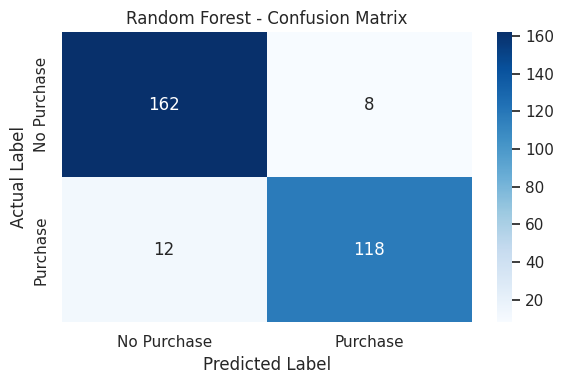

In [11]:

# Calculate the confusion matrix using actual and predicted labels
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Create a figure for the confusion matrix
plt.figure(figsize=(6, 4))

# Draw the confusion matrix as a heatmap with numerical values
sns.heatmap(
    cm,                            # Confusion matrix values
    annot=True,                    # Display counts inside the cells
    fmt="d",                       # Format counts as integers
    cmap="Blues",                  # Use a blue colour scheme
    xticklabels=["No Purchase", "Purchase"],  # Predicted classes
    yticklabels=["No Purchase", "Purchase"]   # Actual classes
)

# Add a title to the graph
plt.title("Random Forest - Confusion Matrix")

# Label the horizontal axis
plt.xlabel("Predicted Label")

# Label the vertical axis
plt.ylabel("Actual Label")

# Adjust spacing so labels fit properly
plt.tight_layout()

# Display the confusion matrix
plt.show()


10.Plot feature importance

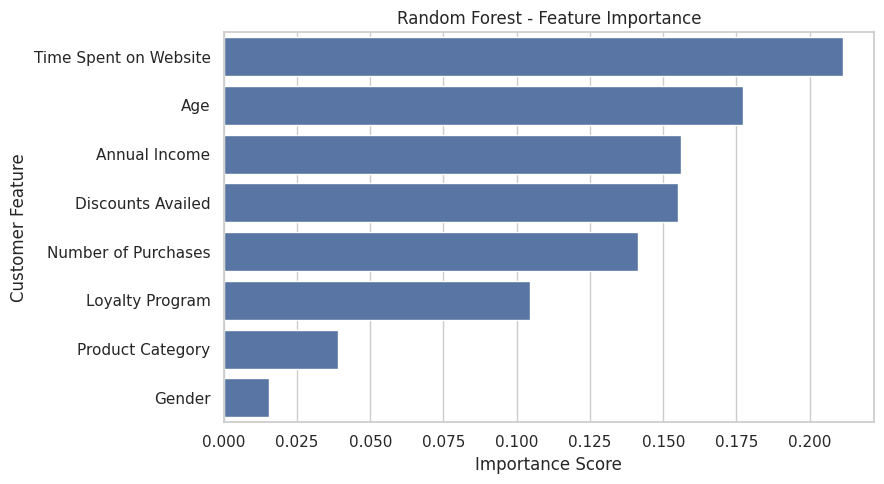

Feature importance ranking:


,Feature,Importance
5,Time Spent on Website,0.211361
0,Age,0.177185
2,Annual Income,0.156203
7,Discounts Availed,0.154912
3,Number of Purchases,0.141539
6,Loyalty Program,0.104462
4,Product Category,0.038947
1,Gender,0.015391


In [12]:

# Create a DataFrame containing feature names and their importance scores
importance_df = pd.DataFrame({
    "Feature": features,                    # Names of the eight input features
    "Importance": model.feature_importances_ # Importance calculated by the model
})

# Sort features from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Create a figure for the feature importance graph
plt.figure(figsize=(9, 5))

# Draw a horizontal bar chart of feature importance scores
sns.barplot(
    data=importance_df,             # Data containing features and scores
    x="Importance",                 # Importance scores on the horizontal axis
    y="Feature"                     # Feature names on the vertical axis
)

# Add a title to the graph
plt.title("Random Forest - Feature Importance")

# Label the horizontal axis
plt.xlabel("Importance Score")

# Label the vertical axis
plt.ylabel("Customer Feature")

# Adjust spacing to prevent labels from being cut off
plt.tight_layout()

# Display the feature importance graph
plt.show()

# Print the features in descending order of importance
print("Feature importance ranking:")

# Display the ranking as a table
display(importance_df)


11.Plot the ROC curve

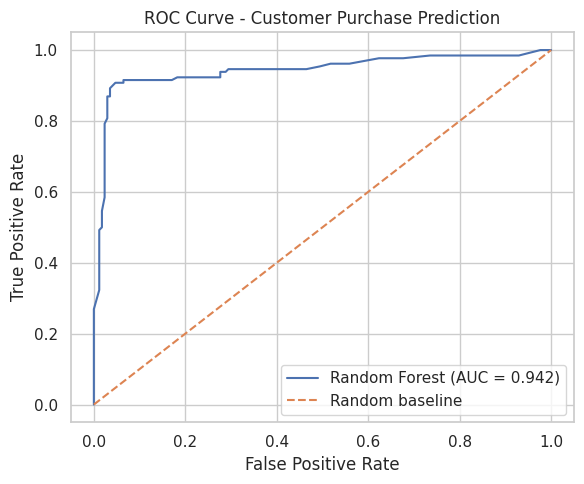

ROC-AUC Score: 0.942


In [13]:

# Get the model's estimated probabilities for the positive class, PurchaseStatus = 1
y_prob = model.predict_proba(X_test)[
    :, list(model.classes_).index(1)
]

# Calculate the false-positive and true-positive rates at different thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate the area under the ROC curve
auc_score = roc_auc_score(y_test, y_prob)

# Create a figure for the ROC curve
plt.figure(figsize=(6, 5))

# Plot the ROC curve using the calculated rates
plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.3f})"
)

# Plot a diagonal line representing random ranking
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

# Add a title to the graph
plt.title("ROC Curve - Customer Purchase Prediction")

# Label the horizontal axis
plt.xlabel("False Positive Rate")

# Label the vertical axis
plt.ylabel("True Positive Rate")

# Display the legend containing the AUC score
plt.legend()

# Adjust the layout
plt.tight_layout()

# Display the ROC curve
plt.show()

# Print the AUC score
print(f"ROC-AUC Score: {auc_score:.3f}")


 12.Predict for a new customer

In [14]:

# Create a DataFrame containing the details of one new customer
new_customer = pd.DataFrame([{
    "Age": 25,                       # Customer is 25 years old
    "Gender": 1,                     # Customer is female
    "Annual Income": 50000,          # Annual income is $50,000
    "Number of Purchases": 5,        # Customer has made 5 purchases
    "Product Category": 0,           # Product category is Electronics
    "Time Spent on Website": 30,     # Customer spent 30 minutes online
    "Loyalty Program": 1,             # Customer is a loyalty member
    "Discounts Availed": 2           # Customer has used 2 discounts
}])

# Arrange the columns in the same order used during model training
new_customer = new_customer[features]

# Apply the imputer learned from the training dataset
new_customer_processed = pd.DataFrame(
    imputer.transform(new_customer),  # Fill missing values if any
    columns=features                   # Preserve the feature names
)

# Predict the purchase status of the new customer
prediction = model.predict(new_customer_processed)[0]

# Calculate the estimated probability for each class
probabilities = model.predict_proba(new_customer_processed)[0]

# Find the position of class 1 in the model's class list
purchase_index = list(model.classes_).index(1)

# Extract the estimated probability of a purchase
purchase_probability = probabilities[purchase_index]

# Display the new customer's details
print("Customer Details:")
display(new_customer)

# Print a heading for the prediction result
print("\nPrediction:")

# Display the predicted class in understandable words
if prediction == 1:
    print("The customer is predicted to make a purchase.")
else:
    print("The customer is predicted not to make a purchase.")

# Display the model's estimated purchase probability as a percentage
print(f"Purchase probability: {purchase_probability * 100:.2f}%")


Customer Details:


,Age,Gender,Annual Income,Number of Purchases,Product Category,Time Spent on Website,Loyalty Program,Discounts Availed
0,25,1,50000,5,0,30,1,2



Prediction:
The customer is predicted not to make a purchase.
Purchase probability: 42.00%


13. Save the trained model and results

In [15]:

# Save the trained Random Forest model to a file
joblib.dump(model, "random_forest_model.pkl")

# Save the fitted imputer so the same preprocessing can be reused
joblib.dump(imputer, "customer_imputer.pkl")

# Save the feature importance table as a CSV file
importance_df.to_csv("feature_importance.csv", index=False)

# Display a heading for the saved files
print("Files saved successfully:")

# Display the saved model's filename
print("1. random_forest_model.pkl")

# Display the saved imputer's filename
print("2. customer_imputer.pkl")

# Display the saved feature importance file's filename
print("3. feature_importance.csv")


Files saved successfully:
1. random_forest_model.pkl
2. customer_imputer.pkl
3. feature_importance.csv
